# 🚲 City Bike-Share Analysis

**SQL + Python analysis of 16 million Capital Bikeshare trips (Washington, DC, May 2020 – Aug 2024)**

---

**Contents**

1. Project overview
2. Business questions
3. Data collection
4. Exploratory data analysis in SQL
5. Data quality and cleaning
6. Visual analysis
7. Key findings
8. Recommendations, limitations and next steps

# 1. Project Overview

A data analysis project focused on understanding bike-sharing usage patterns across a city. The project analyzes trip, rider, bike, station, and weather data to identify trends in ridership, station demand, bike usage, and trip behavior.

The goal is to transform raw data into clear insights and visualizations that can support better operational and business decisions.

**Tech stack:** Python · SQLite · SQL · pandas · NumPy · Matplotlib

# 2. Business Questions

The stakeholders want answers to questions like:

- Which stations are the busiest departure and arrival points, and which are under-used?
- When does demand peak: which hours, weekdays and months?
- How do members and casual riders differ in trip length, timing and fare?
- Are electric bikes ridden longer or more often than classic bikes?
- How much does rain or temperature change daily ridership?

> **Note on fares:** the dataset has no price or fare column, so the *fare* part of the third question cannot be answered. Trip *duration* is used as the closest available proxy for how much a rider uses the service.

cl# 3. Data Collection

Source: [Capital Bikeshare dataset on Kaggle](https://www.kaggle.com/datasets/taweilo/capital-bikeshare-dataset-202005202408)

| Table | Rows | Description |
|---|---|---|
| `daily_rent_detail` | ~16.1 M | One row per trip: bike type, start/end time, start/end station, coordinates, rider type |
| `station_list` | 916 | Station id and name |
| `usage_frequency` | ~873 K | Pickups and dropoffs per station per day |
| `weather` | 1,584 | Daily weather for Washington, DC (temperature, precipitation, wind, conditions) |

The raw CSVs are loaded into a local **SQLite** database so everything can be explored with SQL. The 16 M-row trips file is streamed in chunks to keep memory low.

In [3]:
# Dataset link: https://www.kaggle.com/datasets/taweilo/capital-bikeshare-dataset-202005202408

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("taweilo/capital-bikeshare-dataset-202005202408")

print("Path to dataset files:", path)

Resuming download from 229638144 bytes (353697626 bytes left)...
Resuming download to C:\Users\EXPRESS\.cache\kagglehub\datasets\taweilo\capital-bikeshare-dataset-202005202408\2.archive (229638144/583335770) bytes left.


100%|██████████| 556M/556M [03:05<00:00, 1.91MB/s]

Extracting files...


Path to dataset files: C:\Users\EXPRESS\.cache\kagglehub\datasets\taweilo\capital-bikeshare-dataset-202005202408\versions\2


In [5]:
# Creating database
import pandas as pd
import sqlite3
import os

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
os.makedirs(os.path.join(ROOT, "data"), exist_ok=True)

db = sqlite3.connect(os.path.join(ROOT, "data", "city_bike_share.db"))

In [6]:
file_path = os.path.join(path, "station_list.csv")

df = pd.read_csv(file_path)
df.to_sql("station_list", db, if_exists="replace", index=False)

del df

file_path = os.path.join(path, "weather.csv")

df = pd.read_csv(file_path)
df.to_sql("weather", db, if_exists="replace", index=False)

del df

file_path = os.path.join(path, "usage_frequency.csv")

df = pd.read_csv(file_path)
df.to_sql("usage_frequency", db, if_exists="replace", index=False)

del df


In [7]:
file_path = os.path.join(path, "daily_rent_detail.csv")

first_chunk = True

for chunk in pd.read_csv(file_path, chunksize=50000, low_memory=False):
    chunk.to_sql(
        "daily_rent_detail",
        db,
        if_exists="replace" if first_chunk else "append",
        index=False
    )
    first_chunk = False
    del chunk

# 4. Exploratory Data Analysis (EDA) in SQL

In [8]:
# Creating function for running SQL queries
def run(query):
    return pd.read_sql_query(query, db)

In [9]:
# Identifying the tables
run("""
SELECT name
FROM sqlite_master
WHERE type = 'table';
""")

,name
0,station_list
1,weather
2,usage_frequency
3,daily_rent_detail


In [ ]:
# Identifying the number of rows for each table
run("""
SELECT 'station_list' AS table_name, COUNT(*) AS rows
FROM station_list

UNION ALL

SELECT 'weather', COUNT(*)
FROM weather

UNION ALL

SELECT 'usage_frequency', COUNT(*)
FROM usage_frequency

UNION ALL

SELECT 'daily_rent_clean', COUNT(*)
FROM daily_rent_clean;
""")

,table_name,rows
0,station_list,916
1,weather,1584
2,usage_frequency,873318
3,daily_rent_detail,16086672


In [11]:
# Station_list first 5 rows 
run("SELECT * FROM station_list LIMIT 5")

,station_id,station_name
0,30200,9th St & Pennsylvania Ave NW
1,30201,9th & G St NW
2,31000,Eads St & 15th St S
3,31001,18th St & S Eads St
4,31002,Crystal Dr & 20th St S


In [12]:
# Weather first 5 rows 
run("SELECT * FROM weather LIMIT 5")

,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,"Washington,DC,USA",2020-05-01,18.8,11.6,14.9,18.8,11.6,14.9,8.9,69.6,...,9.5,6,None,2020-05-01T06:09:41,2020-05-01T20:01:16,0.30,"Rain, Partially cloudy",Partly cloudy throughout the day with rain cle...,rain,"KDCA,72405013743,72403793728,F0198,KADW,KDAA,7..."
1,"Washington,DC,USA",2020-05-02,22.1,11.1,16.3,22.1,11.1,16.3,6.4,54.0,...,14.0,9,None,2020-05-02T06:08:30,2020-05-02T20:02:13,0.33,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"KDCA,72405013743,72403793728,F0198,KGAI,KADW,K..."
2,"Washington,DC,USA",2020-05-03,24.9,15.6,18.6,24.9,15.6,18.6,13.4,72.5,...,5.7,4,None,2020-05-03T06:07:21,2020-05-03T20:03:11,0.37,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"KDCA,72405013743,72403793728,F0198,KADW,KDAA,7..."
3,"Washington,DC,USA",2020-05-04,23.8,14.3,19.2,23.8,14.3,19.2,7.8,53.8,...,13.3,8,None,2020-05-04T06:06:12,2020-05-04T20:04:08,0.40,"Rain, Partially cloudy",Clearing in the afternoon with early morning r...,rain,"KDCA,72405013743,72403793728,F0198,KADW,KDAA,7..."
4,"Washington,DC,USA",2020-05-05,14.3,9.3,12.3,14.3,8.0,12.1,3.3,55.6,...,5.0,2,None,2020-05-05T06:05:06,2020-05-05T20:05:05,0.44,"Rain, Partially cloudy",Partly cloudy throughout the day with late aft...,rain,"KIAD,KDCA,72405013743,72403793728,72403093738,..."


In [13]:
# usage_frequency first 5 rows 
run("SELECT * FROM usage_frequency LIMIT 5")

,date,station_name,pickup_counts,dropoff_counts
0,2020-05-01,10th & E St NW,11,7.0
1,2020-05-01,10th & Florida Ave NW,8,8.0
2,2020-05-01,10th & G St NW,3,2.0
3,2020-05-01,10th & K St NW,12,15.0
4,2020-05-01,10th & Monroe St NE,5,6.0


In [ ]:
# Daily_Rent_Detail first 5 rows 
run("SELECT * FROM daily_rent_detail LIMIT 5")

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29,2020-05-31 18:25:22,Anacostia Library,31804,11th & H St NE,31614.0,38.865784,-76.978400,38.899983,-76.991383,casual
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04,2020-05-09 15:06:33,10th & E St NW,31256,21st St & Constitution Ave NW,31261.0,38.895914,-77.026064,38.892459,-77.046567,member
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19,2020-05-24 17:43:51,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268.0,38.934267,-77.057979,38.916787,-77.028139,member
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52,2020-05-27 15:47:13,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119.0,38.934267,-77.057979,38.921074,-77.031887,casual
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03,2020-05-31 14:30:30,Georgia Ave & Morton St NW,31419,17th & K St NW,31213.0,38.932128,-77.023500,38.902760,-77.038630,casual


In [15]:
run("""
PRAGMA table_info(usage_frequency);
""")

,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,station_name,TEXT,0,None,0
2,2,pickup_counts,INTEGER,0,None,0
3,3,dropoff_counts,REAL,0,None,0


In [16]:
run("""
PRAGMA table_info(daily_rent_detail);
""")

,cid,name,type,notnull,dflt_value,pk
0,0,ride_id,TEXT,0,None,0
1,1,rideable_type,TEXT,0,None,0
2,2,started_at,TEXT,0,None,0
3,3,ended_at,TEXT,0,None,0
4,4,start_station_name,TEXT,0,None,0
5,5,start_station_id,INTEGER,0,None,0
6,6,end_station_name,TEXT,0,None,0
7,7,end_station_id,REAL,0,None,0
8,8,start_lat,REAL,0,None,0
9,9,start_lng,REAL,0,None,0


In [17]:
run("""
PRAGMA table_info(station_list);
""")

,cid,name,type,notnull,dflt_value,pk
0,0,station_id,INTEGER,0,None,0
1,1,station_name,TEXT,0,None,0


In [18]:
run("""
PRAGMA table_info(weather);
""")

,cid,name,type,notnull,dflt_value,pk
0,0,name,TEXT,0,None,0
1,1,datetime,TEXT,0,None,0
2,2,tempmax,REAL,0,None,0
3,3,tempmin,REAL,0,None,0
4,4,temp,REAL,0,None,0
5,5,feelslikemax,REAL,0,None,0
6,6,feelslikemin,REAL,0,None,0
7,7,feelslike,REAL,0,None,0
8,8,dew,REAL,0,None,0
9,9,humidity,REAL,0,None,0


In [19]:
run("""
SELECT
    COUNT(*) AS total_rows,
    SUM(ride_id IS NULL) AS ride_id_nulls,
    SUM(rideable_type IS NULL) AS bike_type_nulls,
    SUM(started_at IS NULL) AS started_at_nulls,
    SUM(ended_at IS NULL) AS ended_at_nulls,
    SUM(start_station_name IS NULL) AS start_station_nulls,
    SUM(start_station_id IS NULL) AS start_station_id_nulls,
    SUM(end_station_name IS NULL) AS end_station_nulls,
    SUM(end_station_id IS NULL) AS end_station_id_nulls,
    SUM(member_casual IS NULL) AS rider_type_nulls
FROM daily_rent_detail;
""")

,total_rows,ride_id_nulls,bike_type_nulls,started_at_nulls,ended_at_nulls,start_station_nulls,start_station_id_nulls,end_station_nulls,end_station_id_nulls,rider_type_nulls
0,16086672,0,0,0,0,1450150,1450150,1558268,1558917,0


In [ ]:
# discovering if there are any duplicate ride_id values in the daily_rent_detail table
run("""
SELECT ride_id, COUNT(*) AS count
FROM daily_rent_detail
GROUP BY ride_id
HAVING COUNT(*) > 1
LIMIT 20;
""")

,ride_id,count
0,00E1F539A17F0177,2
1,05A2B6800F89AF43,2
2,071841FB4E2FFDBB,2
3,08DBAFFB21384C21,2
4,0D143E0F540FC12B,2
5,0DC098B182A008CE,2
6,11A6A001B4244CB4,2
7,11BA31BB263B07B7,2
8,120FF0AC298E453D,2
9,14241BBF3C7B2272,2


In [21]:
#counting the number of rows for each ride_id and checking if there are any duplicate ride_id values in the daily_rent_detail table
run("""
SELECT
    ride_id,
    COUNT(*) AS rows_count,
    COUNT(DISTINCT rideable_type) AS bike_types,
    COUNT(DISTINCT started_at) AS start_times,
    COUNT(DISTINCT ended_at) AS end_times,
    COUNT(DISTINCT start_station_id) AS start_stations,
    COUNT(DISTINCT end_station_id) AS end_stations,
    COUNT(DISTINCT member_casual) AS rider_types
FROM daily_rent_detail
GROUP BY ride_id
HAVING COUNT(*) > 1;
""")

,ride_id,rows_count,bike_types,start_times,end_times,start_stations,end_stations,rider_types
0,00E1F539A17F0177,2,1,2,2,1,1,1
1,05A2B6800F89AF43,2,1,2,2,0,0,1
2,071841FB4E2FFDBB,2,1,2,2,1,1,1
3,08DBAFFB21384C21,2,1,2,2,1,1,1
4,0D143E0F540FC12B,2,1,2,2,1,1,1
...,...,...,...,...,...,...,...,...
136,F3E3AE9BB2AF3FB3,2,1,2,2,1,0,1
137,F5F3789644A8F3D5,2,1,2,2,1,1,1
138,F8D94C242525FD8C,2,1,2,2,0,0,1
139,FE68E0DF3651E5EA,2,1,2,2,1,1,1


In [22]:
# show duplicated trips whether they are the same trip or different trips
run("""
SELECT *
FROM daily_rent_detail
WHERE ride_id = '00E1F539A17F0177';
""")

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,00E1F539A17F0177,classic_bike,2024-05-31 18:40:35,2024-06-01 14:30:47,Connecticut Ave & Ordway St NW / Cleveland Par...,31338,34th & Water St NW,31314.0,38.935842,-77.058468,38.903731,-77.067528,casual
1,00E1F539A17F0177,classic_bike,2024-05-31 18:40:35.532,2024-06-01 14:30:47.202,Connecticut Ave & Ordway St NW / Cleveland Par...,31338,34th & Water St NW,31314.0,38.935842,-77.058468,38.903731,-77.067528,casual


In [23]:
run("""
SELECT COUNT(*) AS duplicated_ride_ids
FROM (
    SELECT ride_id
    FROM daily_rent_detail
    GROUP BY ride_id
    HAVING COUNT(*) > 1
);
""")

,duplicated_ride_ids
0,141


In [24]:
run("""
SELECT rideable_type, COUNT(*) AS count
FROM daily_rent_detail
GROUP BY rideable_type;
""")

,rideable_type,count
0,classic_bike,9614139
1,docked_bike,1855785
2,electric_bike,4616748


In [25]:
run("""
SELECT member_casual, COUNT(*) AS count
FROM daily_rent_detail
GROUP BY member_casual;
""")

,member_casual,count
0,casual,6293515
1,member,9793157


In [26]:
run("""
SELECT
    MIN(started_at) AS earliest_trip,
    MAX(started_at) AS latest_trip
FROM daily_rent_detail;
""")

,earliest_trip,latest_trip
0,2020-05-01 00:02:02,2024-08-31 23:57:12.743


In [27]:
#showing trips with end_date starts before the start_date
run("""
SELECT COUNT(*) AS invalid_trips
FROM daily_rent_detail
WHERE ended_at < started_at;
""")

,invalid_trips
0,8617


In [28]:
#creating new table without duplicated and invalid trips
db.executescript("""
DROP TABLE IF EXISTS daily_rent_clean;

CREATE TABLE daily_rent_clean AS
SELECT *
FROM daily_rent_detail
WHERE ended_at >= started_at
  AND rowid IN (
      SELECT MIN(rowid)
      FROM daily_rent_detail
      GROUP BY ride_id
  );
""")

db.commit()

In [29]:
#showing cleanded data
run("""
SELECT COUNT(*) AS clean_rows
FROM daily_rent_clean;
""")

,clean_rows
0,16077914


How many bikes of each type (Classic / Electric/ Docked) does the fleet have, and how many riders are Members vs Casual?


In [30]:
run(
  """SELECT DISTINCT rideable_type
  FROM daily_rent_clean;""")

,rideable_type
0,docked_bike
1,electric_bike
2,classic_bike


In [31]:
run("""
SELECT
    rideable_type,
    member_casual,
    COUNT(*) AS number_of_rides
FROM daily_rent_clean
GROUP BY rideable_type, member_casual
ORDER BY number_of_rides DESC;
""")

,rideable_type,member_casual,number_of_rides
0,classic_bike,member,6232491
1,classic_bike,casual,3381248
2,electric_bike,member,2863357
3,electric_bike,casual,1752132
4,docked_bike,casual,1157076
5,docked_bike,member,691610


In [32]:
run ("""SELECT member_casual, COUNT(*) AS number_of_rides
FROM daily_rent_clean
GROUP BY member_casual
ORDER BY number_of_rides DESC;""")

,member_casual,number_of_rides
0,member,9787458
1,casual,6290456


In [33]:
run("""SELECT
    rideable_type,
    member_casual,
    COUNT(*) AS number_of_rides
    FROM daily_rent_clean
    GROUP BY rideable_type, member_casual
    ORDER BY rideable_type, member_casual;""")

,rideable_type,member_casual,number_of_rides
0,classic_bike,casual,3381248
1,classic_bike,member,6232491
2,docked_bike,casual,1157076
3,docked_bike,member,691610
4,electric_bike,casual,1752132
5,electric_bike,member,2863357


The longest 10 trips (by duration) taken in July 2024 with start time, duration.

In [34]:
run("""SELECT ride_id,started_at, ended_at, cast((julianday(ended_at) - julianday(started_at))*24*60 AS INTEGER) AS "Duration In Minutes"
FROM daily_rent_clean
WHERE started_at LIKE '2024-07%'
ORDER BY "Duration In Minutes" DESC
LIMIT 10
""")

,ride_id,started_at,ended_at,Duration In Minutes
0,EE1BCA5F1D81AAB2,2024-07-23 09:54:43.562,2024-07-24 10:54:39.635,1499
1,F95C062EC5BA5D8A,2024-07-21 12:50:15.911,2024-07-22 13:50:11.171,1499
2,FF70D840F9269C80,2024-07-04 21:54:57.764,2024-07-05 22:54:37.079,1499
3,BF4DF215A31CF7AA,2024-07-26 19:08:38.083,2024-07-27 20:08:31.741,1499
4,F4789DDBB3DD0952,2024-07-08 10:11:01.609,2024-07-09 11:10:57.932,1499
5,C908D9CE0503B91F,2024-07-26 21:52:33.966,2024-07-27 22:52:28.168,1499
6,F46DCA4A2B4B78E2,2024-07-07 12:56:24.738,2024-07-08 13:56:21.002,1499
7,3AD6C6F7371760C7,2024-07-18 10:05:57.485,2024-07-19 11:05:52.408,1499
8,542457F72918517B,2024-07-21 16:10:21.882,2024-07-22 17:10:01.260,1499
9,9DB8FBE7973131E2,2024-07-05 15:17:10.679,2024-07-06 16:16:49.036,1499


Total number of trips, average duration; then the same broken down by month of 2024.

In [35]:
run("""
SELECT count(ride_id) AS total_trips,
avg((julianday(ended_at) - julianday(started_at))*24*60) AS avg_trip_duration,
strftime('%m', started_at) AS month
FROM daily_rent_clean
WHERE started_at >= '2024-01-01'
  AND started_at < '2025-01-01'
  GROUP BY strftime('%m', started_at);
""")

,total_trips,avg_trip_duration,month
0,238790,14.773346,01
1,318643,14.620654,02
2,436902,18.046906,03
3,490185,17.055650,04
4,515331,17.340154,05
5,584357,18.176259,06
6,589443,17.576907,07
7,614564,16.621988,08


At which hour of the day do most trips start? Show trips per hour (0-23). (Hint: strftime('%H', start_time).)

In [36]:
run ("""SELECT strftime('%H', started_at) AS hour_of_day, COUNT(*) AS number_of_trips
        FROM daily_rent_clean
        GROUP BY hour_of_day
        ORDER BY number_of_trips DESC;""")

,hour_of_day,number_of_trips
0,17,1576183
1,18,1404583
2,16,1259291
3,15,1127247
4,19,1063538
5,14,1013272
6,13,984051
7,12,961119
8,08,937478
9,11,837520


Trips per day of week: which weekday is the busiest and which is the quietest?

In [37]:
run("""SELECT
    CASE strftime('%w', started_at)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS Day,
    COUNT(DISTINCT ride_id) AS Number_of_Trips
FROM daily_rent_clean
GROUP BY Day
ORDER BY Number_of_Trips DESC
""")
# After analysis: The busiest day is Saturday, while the quietest day is Monday.

,Day,Number_of_Trips
0,Saturday,2598354
1,Friday,2322122
2,Thursday,2296866
3,Wednesday,2285941
4,Tuesday,2253280
5,Sunday,2250196
6,Monday,2071155


Which 10 stations have the most departures? Show station name, and number of trips started there.


In [38]:
run("""
SELECT
    station_list.station_name,
    COUNT(daily_rent_clean.start_station_id) AS trip_count
FROM daily_rent_clean
JOIN station_list ON
    daily_rent_clean.start_station_id = station_list.station_id
GROUP BY station_list.station_name
ORDER BY trip_count DESC
LIMIT 10;
""")

,station_name,trip_count
0,New Hampshire Ave & T St NW,153568
1,Columbus Circle / Union Station,147326
2,15th & P St NW,140745
3,Lincoln Memorial,138583
4,1st & M St NE,130314
5,Jefferson Dr & 14th St SW,125712
6,4th St & Madison Dr NW,120464
7,14th & V St NW,117147
8,5th & K St NW,114259
9,Eastern Market Metro / Pennsylvania Ave & 8th ...,113265


For every station, compare departures vs arrivals and compute
the net flow (arrivals - departures). Which stations tend to fill up and which empty out? (Hint: join stations to trips twice, or UNION two aggregates.)

In [39]:
run("""
SELECT
    station_id,
    SUM(departures) AS departures,
    SUM(arrivals) AS arrivals,
    SUM(arrivals) - SUM(departures) AS net_flow
FROM (

    SELECT
        start_station_id AS station_id,
        COUNT(*) AS departures,
        0 AS arrivals
    FROM daily_rent_clean
    WHERE start_station_id IS NOT NULL
    GROUP BY start_station_id

    UNION ALL

    SELECT
        end_station_id AS station_id,
        0 AS departures,
        COUNT(*) AS arrivals
    FROM daily_rent_clean
    WHERE end_station_id IS NOT NULL
    GROUP BY end_station_id

)
GROUP BY station_id
ORDER BY net_flow DESC;
""")


,station_id,departures,arrivals,net_flow
0,31215,49164,65218,16054
1,31293,31264,45314,14050
2,31225,43760,57653,13893
3,31230,57201,68747,11546
4,31314,38782,49710,10928
...,...,...,...,...
804,31296,71084,55494,-15590
805,31131,50568,34175,-16393
806,31124,91617,74403,-17214
807,31602,62616,41044,-21572


Member VS casual riders: number of trips and average duration?

In [40]:
run("""SELECT member_casual, COUNT(*) AS number_of_trips,
avg((julianday(ended_at) - julianday(started_at))*24*60) AS avg_trip_duration
FROM daily_rent_clean
GROUP BY member_casual;
""")

,member_casual,number_of_trips,avg_trip_duration
0,casual,6290456,39.272738
1,member,9787458,14.467027


Does weather matter? Join trips to daily_weather and compare average trips per day for Sunny, Cloudy, Windy and Rainy days.

In [41]:
run("""SELECT w.conditions, AVG(daily_trips) AS "Average Trips Per Day"
FROM (SELECT DATE(started_at) AS ride_date, COUNT(*) AS daily_trips
    FROM daily_rent_clean
    GROUP BY ride_date) sq
JOIN weather w
ON sq.ride_date = w.datetime
GROUP BY w.conditions""")

,conditions,Average Trips Per Day
0,Clear,10569.884615
1,Overcast,7737.702703
2,Partially cloudy,10981.071429
3,"Rain, Freezing Drizzle/Freezing Rain, Overcast",5282.000000
4,"Rain, Freezing Drizzle/Freezing Rain, Partiall...",7154.000000
5,"Rain, Ice, Overcast",3430.000000
6,"Rain, Overcast",7569.872340
7,"Rain, Partially cloudy",10492.872180
8,"Snow, Partially cloudy",3344.500000
9,"Snow, Rain, Freezing Drizzle/Freezing Rain, Ic...",2786.000000


# 5. Data Quality and Cleaning

Before visualising anything, I audit the trip table. Three issues showed up in the EDA:

1. **Negative durations**: trip ends before it starts (data-entry or clock errors).
2. **Very short trips** (< 1 minute): false starts, where a bike is undocked and immediately re-docked.
3. **Very long trips** (> 24 hours): bikes that were never returned properly (durations are capped around 1,499 minutes).

Missing station ids are also counted; they mostly come from dockless e-bike trips that start or end away from a station.

In [ ]:
# How many trips have impossible or suspicious values?
audit = run("""
SELECT
    COUNT(*)                          AS total_trips,
    SUM(dur < 0)                      AS negative_duration,
    SUM(dur >= 0 AND dur < 1)         AS under_1_minute,
    SUM(dur > 1440)                   AS over_24_hours,
    SUM(start_station_id IS NULL)     AS missing_start_station,
    SUM(end_station_id   IS NULL)     AS missing_end_station
FROM (
    SELECT (julianday(ended_at) - julianday(started_at)) * 1440.0 AS dur,
           start_station_id,
           end_station_id
    FROM daily_rent_clean
)
""")
display(audit)

audit_pct = (audit.iloc[0, 1:].astype(float) / audit.iloc[0, 0] * 100).round(3)
display(audit_pct.rename("% of all trips").to_frame())

,total_trips,negative_duration,under_1_minute,over_24_hours,missing_start_station,missing_end_station
0,16077914,0,265623,21335,1449299,1558333


,% of all trips
negative_duration,0.000
under_1_minute,1.652
over_24_hours,0.133
missing_start_station,9.014
missing_end_station,9.692


### Cleaning rules

I create one cleaned table, `trips_clean`, and run every chart query against it. The rules (also in `sql/02_data_cleaning.sql`; the matching audit queries are in `sql/01_data_quality_audit.sql`):

1. remove **duplicate** `ride_id`s (keep the first)
2. drop rows with missing or unparseable timestamps
3. **standardise text**: trim spaces, lower-case categories, blank station names become `NULL`
4. keep only valid bike types (classic / electric / docked) and rider types (member / casual)
5. set coordinates outside the Washington, DC area (or `0,0`) to `NULL`
6. keep trips lasting **1 minute to 24 hours**
7. add ready-to-use columns: `duration_min`, `trip_date`, `year`, `month`, `hour`, `dow` (0 = Sunday)

The raw table is left untouched so the cleaning is fully reproducible. This step takes a few minutes on the full dataset.

In [43]:
# Same script as sql/02_data_cleaning.sql
db.executescript("""-- =============================================================================
-- 02 | DATA CLEANING  ->  creates the table `trips_clean`
--
-- Rules applied
--   1. Remove duplicate rows (same ride_id): keep the first occurrence
--   2. Drop rows with missing ride_id / timestamps / unparseable timestamps
--   3. Standardise text: trim spaces, lower-case categories, blank -> NULL
--   4. Keep only valid categories (3 bike types, 2 rider types)
--   5. Null out coordinates outside the Washington, DC metro area
--   6. Keep trips lasting 1 minute to 24 hours (drops negatives, false starts,
--      and bikes that were never returned)
--   7. Add derived columns: duration_min, trip_date, year, month, hour, dow
-- =============================================================================

DROP TABLE IF EXISTS trips_clean;

CREATE TABLE trips_clean AS
SELECT
    t.ride_id,
    LOWER(TRIM(t.rideable_type))                              AS rideable_type,
    LOWER(TRIM(t.member_casual))                              AS member_casual,
    t.started_at,
    t.ended_at,
    t.start_station_id,
    CAST(t.end_station_id AS INTEGER)                         AS end_station_id,
    NULLIF(TRIM(t.start_station_name), '')                    AS start_station_name,
    NULLIF(TRIM(t.end_station_name), '')                      AS end_station_name,
    CASE WHEN t.start_lat BETWEEN 38.6 AND 39.3 AND t.start_lng BETWEEN -77.7 AND -76.6
         THEN t.start_lat END                                 AS start_lat,
    CASE WHEN t.start_lat BETWEEN 38.6 AND 39.3 AND t.start_lng BETWEEN -77.7 AND -76.6
         THEN t.start_lng END                                 AS start_lng,
    CASE WHEN t.end_lat BETWEEN 38.6 AND 39.3 AND t.end_lng BETWEEN -77.7 AND -76.6
         THEN t.end_lat END                                   AS end_lat,
    CASE WHEN t.end_lat BETWEEN 38.6 AND 39.3 AND t.end_lng BETWEEN -77.7 AND -76.6
         THEN t.end_lng END                                   AS end_lng,
    (julianday(t.ended_at) - julianday(t.started_at)) * 1440.0 AS duration_min,
    DATE(t.started_at)                                        AS trip_date,
    CAST(strftime('%Y', t.started_at) AS INTEGER)             AS year,
    CAST(strftime('%m', t.started_at) AS INTEGER)             AS month,
    CAST(strftime('%H', t.started_at) AS INTEGER)             AS hour,
    CAST(strftime('%w', t.started_at) AS INTEGER)             AS dow   -- 0 = Sunday
FROM daily_rent_detail AS t
WHERE t.rowid IN (                                   -- rule 1: de-duplicate
          SELECT MIN(rowid) FROM daily_rent_detail
          WHERE ride_id IS NOT NULL
          GROUP BY ride_id)
  AND t.started_at IS NOT NULL                       -- rule 2
  AND t.ended_at   IS NOT NULL
  AND julianday(t.started_at) IS NOT NULL
  AND julianday(t.ended_at)   IS NOT NULL
  AND LOWER(TRIM(t.rideable_type)) IN ('classic_bike', 'electric_bike', 'docked_bike')   -- rule 4
  AND LOWER(TRIM(t.member_casual)) IN ('member', 'casual')
  AND (julianday(t.ended_at) - julianday(t.started_at)) * 1440.0 BETWEEN 1 AND 1440;     -- rule 6

-- Post-clean validation (should show 0 problems)
-- SELECT COUNT(*) total, COUNT(DISTINCT ride_id) distinct_ids,
--        MIN(duration_min) min_dur, MAX(duration_min) max_dur FROM trips_clean;
""")
db.commit()

n_raw   = int(run("SELECT COUNT(*) AS n FROM daily_rent_clean")["n"][0])
n_clean = int(run("SELECT COUNT(*) AS n FROM trips_clean")["n"][0])
print(f"Raw trips     : {n_raw:,}")
print(f"Clean trips   : {n_clean:,}")
print(f"Rows removed  : {n_raw - n_clean:,} ({(n_raw - n_clean) / n_raw:.2%})")

Raw trips     : 16,086,672
Clean trips   : 15,790,956
Rows removed  : 295,716 (1.84%)


In [44]:
run("""
SELECT month,
       COUNT(*)                        AS trips,
       ROUND(AVG(duration_min), 2)     AS avg_duration_min,
       ROUND(MIN(duration_min), 2)     AS min_duration_min,
       ROUND(MAX(duration_min), 2)     AS max_duration_min
FROM trips_clean
WHERE year = 2024
GROUP BY month
ORDER BY month
""")

,month,trips,avg_duration_min,min_duration_min,max_duration_min
0,1,233671,13.63,1.0,1433.05
1,2,312494,13.60,1.0,1438.38
2,3,427349,16.94,1.0,1439.95
3,4,479844,16.13,1.0,1439.90
4,5,504151,16.41,1.0,1433.52
5,6,574732,16.86,1.0,1438.30
6,7,579951,16.38,1.0,1437.34
7,8,603766,15.78,1.0,1431.63


# 6. Visual Analysis

In [45]:
# ---- Setup for the visual analysis ----
import sys
import numpy as np
import matplotlib.pyplot as plt

if not os.path.exists(os.path.join(ROOT, "src", "plots.py")):
    raise FileNotFoundError("src/plots.py not found. Clone the full repository and run the notebook from the notebooks/ folder.")
sys.path.insert(0, ROOT)
from src import plots

IMG = os.path.join(ROOT, "images")     # charts are saved here
os.makedirs(IMG, exist_ok=True)

DAY_NAMES = {0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
             4: "Thursday", 5: "Friday", 6: "Saturday"}
pd.options.display.float_format = "{:,.2f}".format

## 6.1 Fleet and rider mix

**Question:** how are rides split between classic, electric and docked bikes, and between members and casual riders?


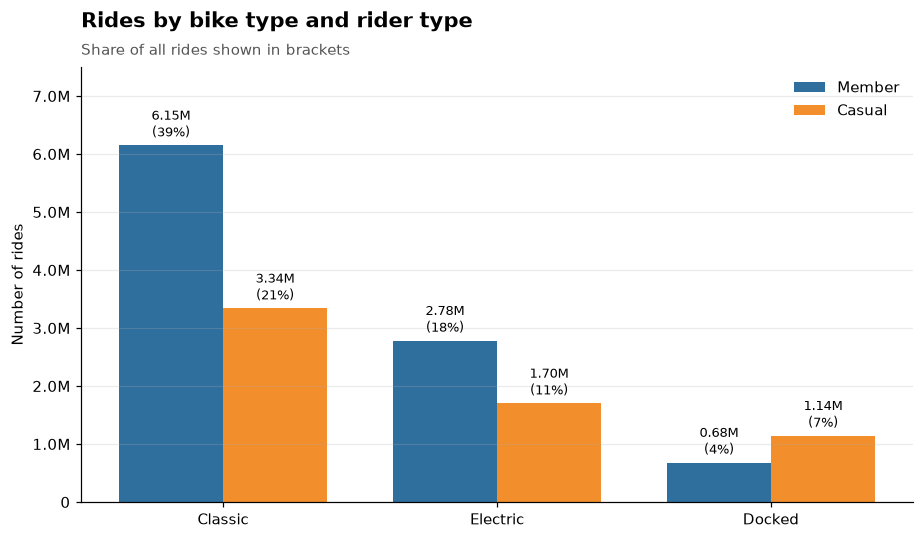

Members take 61% of rides, casual riders 39%.
Share of rides by bike type: classic 60%, electric 28%, docked 12%


In [46]:
fleet = run("""
SELECT rideable_type,
       member_casual,
       COUNT(*)           AS number_of_rides,
       AVG(duration_min)  AS avg_duration_min
FROM trips_clean
GROUP BY rideable_type, member_casual
""")

plots.plot_fleet_mix(fleet, f"{IMG}/01_rides_by_bike_and_rider_type.png")
plt.show()

total = fleet["number_of_rides"].sum()
by_rider = fleet.groupby("member_casual")["number_of_rides"].sum() / total
by_bike = fleet.groupby("rideable_type")["number_of_rides"].sum() / total
print(f"Members take {by_rider['member']:.0%} of rides, casual riders {by_rider['casual']:.0%}.")
print("Share of rides by bike type: " + ", ".join(f"{k.replace('_bike', '')} {v:.0%}" for k, v in by_bike.sort_values(ascending=False).items()))

## 6.2 When does demand peak?

**Questions:** which hours, weekdays and months are busiest, and do members and casual riders ride at different times?

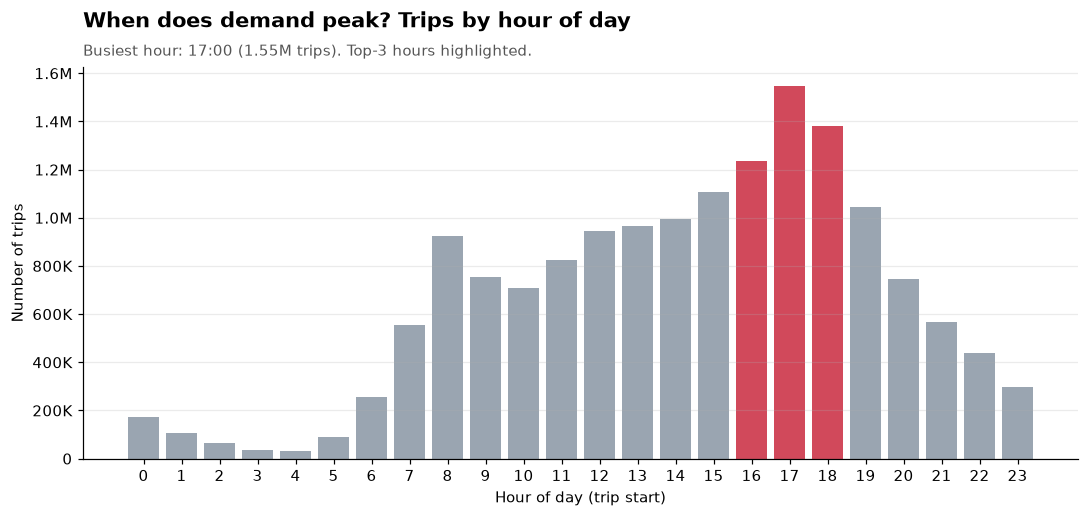

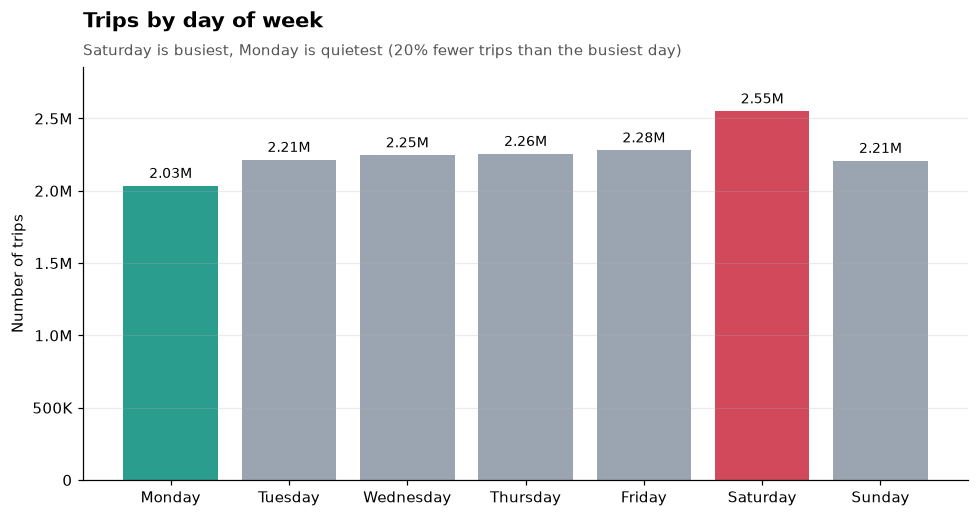

In [47]:
# One pass over the data gives us hour x weekday x rider type; everything else is derived in pandas
dh = run("""
SELECT dow, hour AS hour_of_day, member_casual, COUNT(*) AS number_of_trips
FROM trips_clean
GROUP BY dow, hour, member_casual
""")
dh["Day"] = dh["dow"].map(DAY_NAMES)

hourly_overall = dh.groupby("hour_of_day", as_index=False)["number_of_trips"].sum()
hourly_rider = dh.groupby(["hour_of_day", "member_casual"], as_index=False)["number_of_trips"].sum()
weekday = (dh.groupby("Day", as_index=False)["number_of_trips"].sum()
             .rename(columns={"number_of_trips": "Number_of_Trips"}))

plots.plot_hourly_overall(hourly_overall, f"{IMG}/02_trips_by_hour.png")
plt.show()
plots.plot_weekday(weekday, f"{IMG}/03_trips_by_weekday.png")
plt.show()

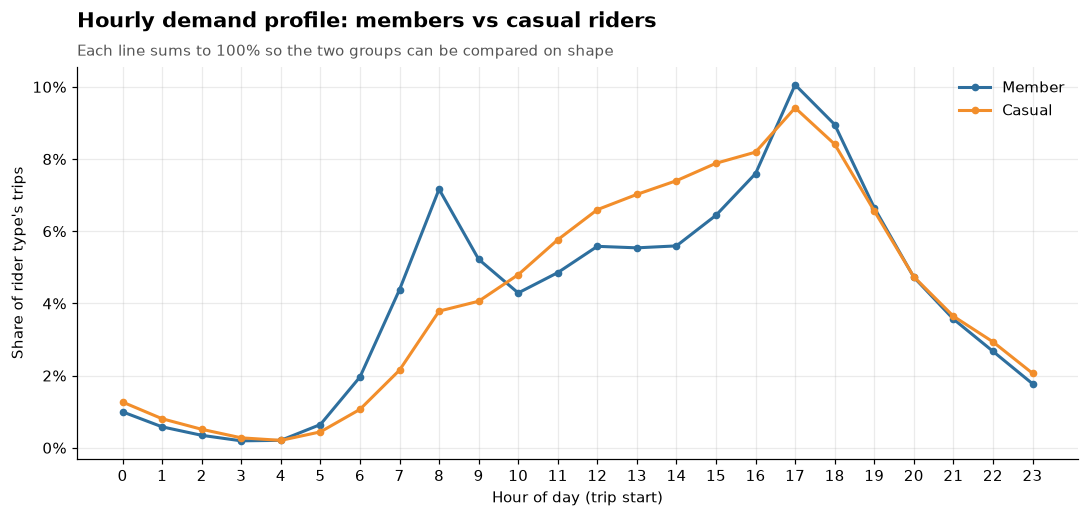

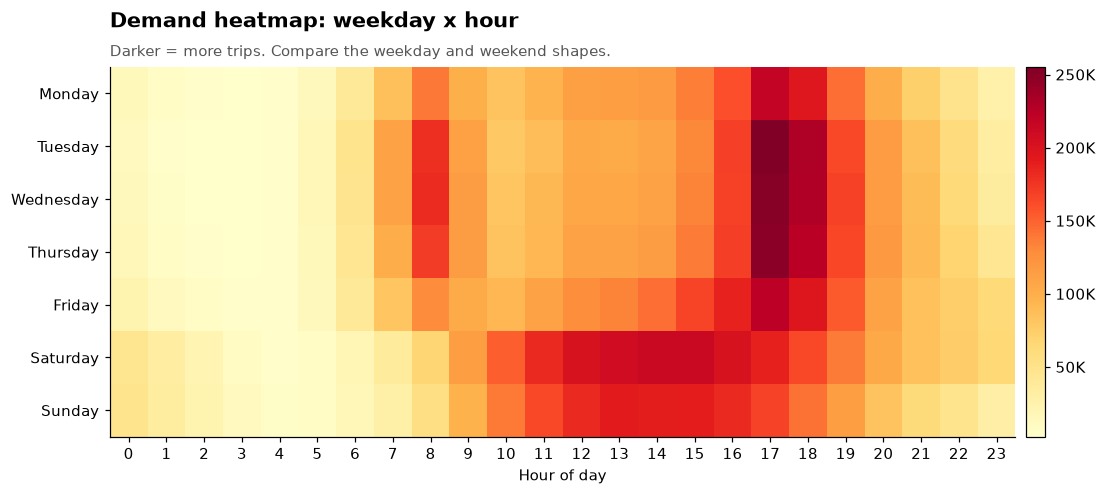

Overall peak hour: 17:00. Morning peak: 08:00.
Member : 35% of trips are weekday commute-hour trips (7-9h, 16-18h); 26% happen on weekends.
Casual : 25% of trips are weekday commute-hour trips (7-9h, 16-18h); 37% happen on weekends.


In [48]:
plots.plot_hourly_by_rider(hourly_rider, f"{IMG}/06_hourly_profile_by_rider_type.png")
plt.show()
plots.plot_heatmap(dh.groupby(["Day", "hour_of_day"], as_index=False)["number_of_trips"].sum(),
                   f"{IMG}/07_weekday_hour_heatmap.png")
plt.show()

# Computed takeaways
peak = hourly_overall.loc[hourly_overall["number_of_trips"].idxmax()]
am = hourly_overall[hourly_overall["hour_of_day"].between(6, 10)]
am_peak = am.loc[am["number_of_trips"].idxmax()]
print(f"Overall peak hour: {int(peak['hour_of_day']):02d}:00. Morning peak: {int(am_peak['hour_of_day']):02d}:00.")

commute_hours = [7, 8, 9, 16, 17, 18]
for rider in ["member", "casual"]:
    r = dh[dh["member_casual"] == rider]
    total_r = r["number_of_trips"].sum()
    commute = r[r["dow"].between(1, 5) & r["hour_of_day"].isin(commute_hours)]["number_of_trips"].sum()
    weekend = r[r["dow"].isin([0, 6])]["number_of_trips"].sum()
    print(f"{rider.title():7s}: {commute / total_r:.0%} of trips are weekday commute-hour trips (7-9h, 16-18h); "
          f"{weekend / total_r:.0%} happen on weekends.")

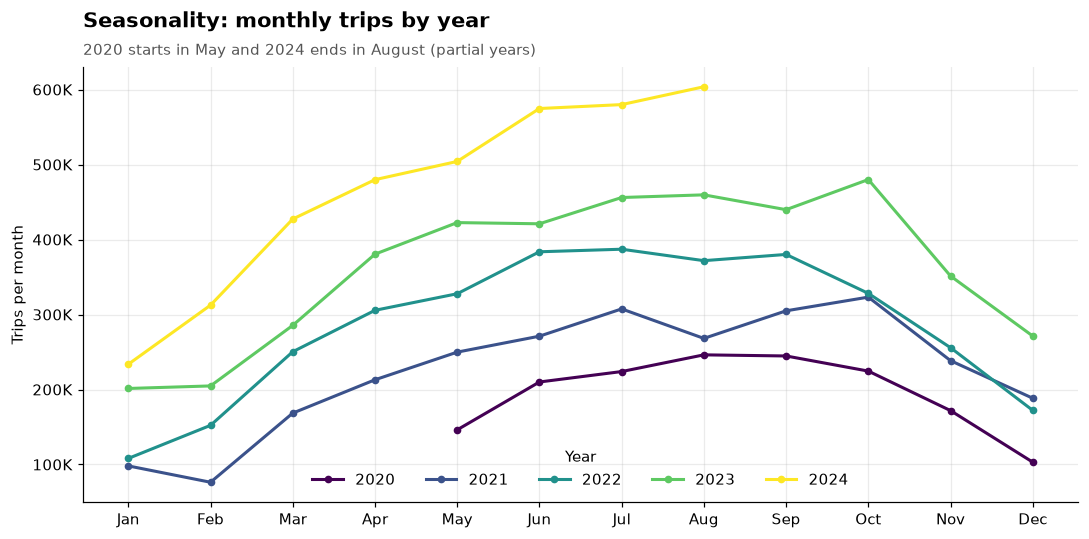

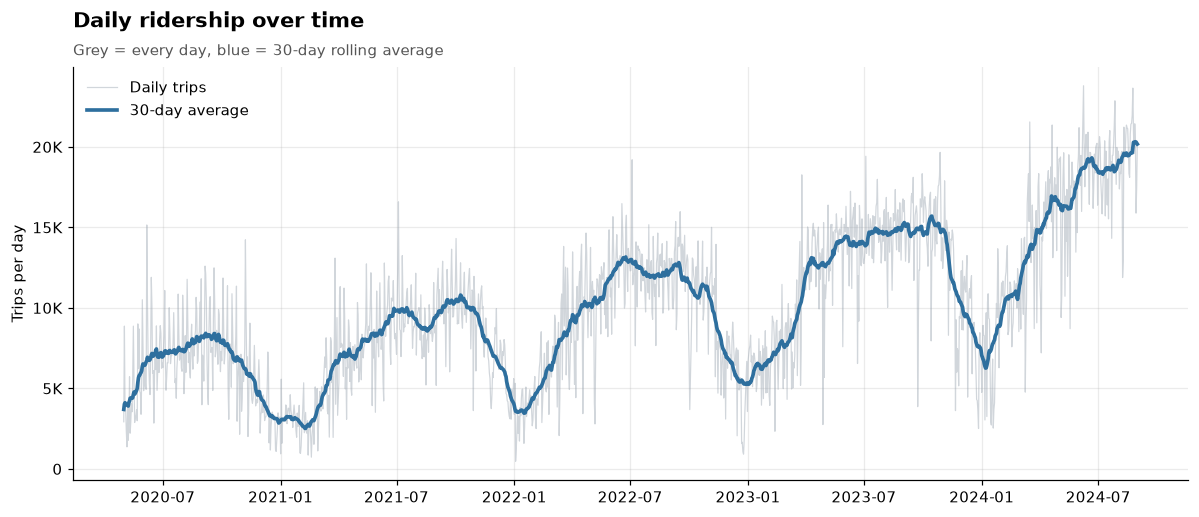

Best month on average: July (12,610 trips/day). Quietest: January (5,172 trips/day).


,trips,months_of_data
year,,
2020,1570658,8
2021,2707549,12
2022,3422888,12
2023,4373903,12
2024,3715958,8


In [49]:
mb = run("""
SELECT year, month, rideable_type, COUNT(*) AS trips
FROM trips_clean
GROUP BY year, month, rideable_type
""")
monthly = mb.groupby(["year", "month"], as_index=False)["trips"].sum()
daily = run("SELECT trip_date, COUNT(*) AS trips FROM trips_clean GROUP BY trip_date")

plots.plot_monthly_trend(monthly, f"{IMG}/08_monthly_trips_by_year.png")
plt.show()
plots.plot_daily_trend(daily, f"{IMG}/09_daily_trips_trend.png")
plt.show()

# Computed takeaways: normalise by days in the data so partial years/months are fair
daily["month"] = pd.to_datetime(daily["trip_date"]).dt.month
per_day = daily.groupby("month")["trips"].mean()
print(f"Best month on average: {pd.Timestamp(2000, int(per_day.idxmax()), 1):%B} ({per_day.max():,.0f} trips/day). "
      f"Quietest: {pd.Timestamp(2000, int(per_day.idxmin()), 1):%B} ({per_day.min():,.0f} trips/day).")
yearly = monthly.groupby("year")["trips"].agg(["sum", "count"]).rename(columns={"sum": "trips", "count": "months_of_data"})
display(yearly)

### Are electric bikes ridden more often?

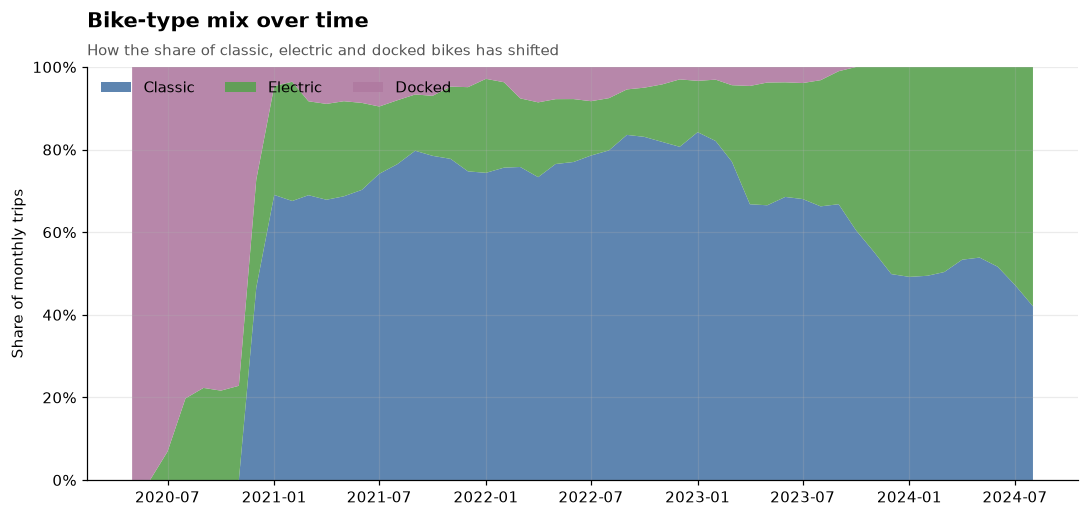

rideable_type,classic_bike (% of trips),docked_bike (% of trips),electric_bike (% of trips)
year,,,
2020,3.10,82.10,14.90
2021,73.80,7.40,18.90
2022,78.70,6.50,14.80
2023,66.50,2.60,30.90
2024,49.40,0.00,50.60


In [50]:
plots.plot_bike_share_trend(mb, f"{IMG}/10_bike_type_share_over_time.png")
plt.show()

by_year = mb.pivot_table(index="year", columns="rideable_type", values="trips", aggfunc="sum").fillna(0)
share = by_year.div(by_year.sum(axis=1), axis=0)
display((share * 100).round(1).add_suffix(" (% of trips)"))

## 6.3 Members vs casual riders

**how do trip length and behaviour differ between members and casual riders, and between bike types?


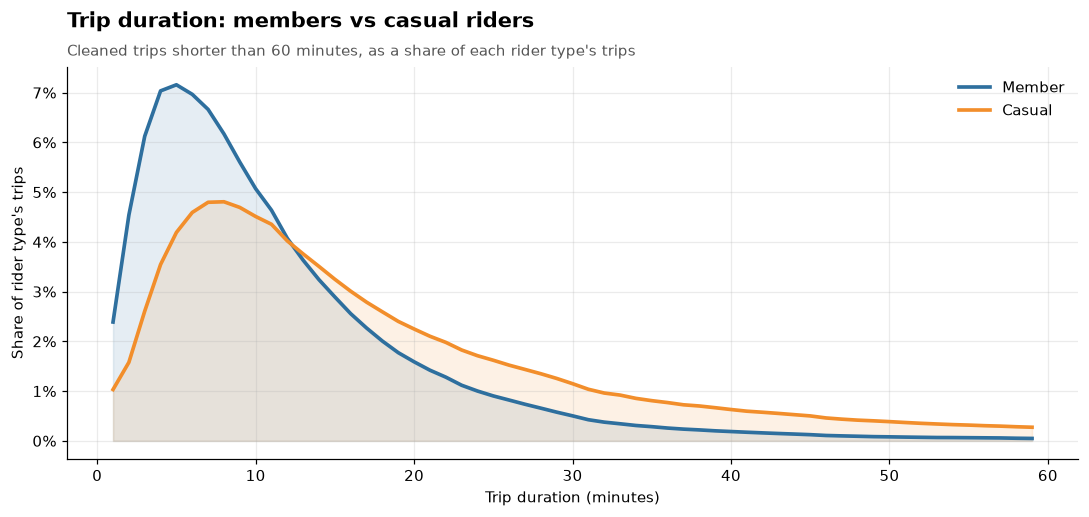

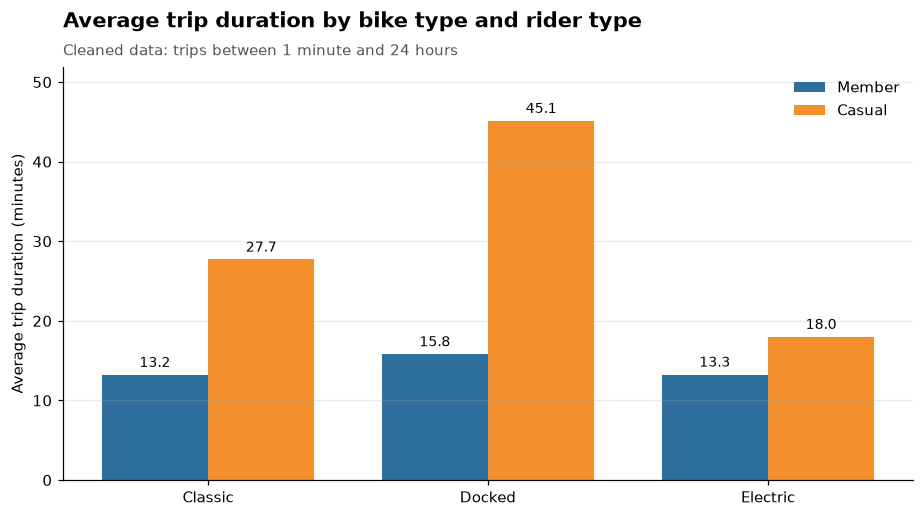

Average trip: members 13.4 min vs casual 28.3 min (casual trips are 2.1x longer).
Average trip by bike type (min): classic 18.3, docked 34.2, electric 15.1
Share of trips (under 60 min) shorter than 10 min: members 53%, casual 32%.


In [51]:
dist = run("""
SELECT member_casual,
       CAST(duration_min AS INTEGER) AS minute,
       COUNT(*)                      AS trips
FROM trips_clean
WHERE duration_min < 60
GROUP BY member_casual, minute
""")

plots.plot_duration_distribution(dist, f"{IMG}/11_trip_duration_distribution.png")
plt.show()
plots.plot_avg_duration(fleet, f"{IMG}/12_avg_duration_by_bike_and_rider.png")
plt.show()

# Computed takeaways (weighted averages across bike types)
fleet["total_min"] = fleet["avg_duration_min"] * fleet["number_of_rides"]
g = fleet.groupby("member_casual")[["total_min", "number_of_rides"]].sum()
avg_by_rider = g["total_min"] / g["number_of_rides"]
print(f"Average trip: members {avg_by_rider['member']:.1f} min vs casual {avg_by_rider['casual']:.1f} min "
      f"(casual trips are {avg_by_rider['casual'] / avg_by_rider['member']:.1f}x longer).")

g2 = fleet.groupby("rideable_type")[["total_min", "number_of_rides"]].sum()
avg_by_bike = (g2["total_min"] / g2["number_of_rides"]).round(1)
print("Average trip by bike type (min): " + ", ".join(f"{k.replace('_bike', '')} {v}" for k, v in avg_by_bike.items()))

short = dist[dist["minute"] < 10].groupby("member_casual")["trips"].sum() / dist.groupby("member_casual")["trips"].sum()
print(f"Share of trips (under 60 min) shorter than 10 min: members {short['member']:.0%}, casual {short['casual']:.0%}.")

## 6.4 Stations

**which stations are the busiest departure points, which are under-used, and which fill up or empty out?

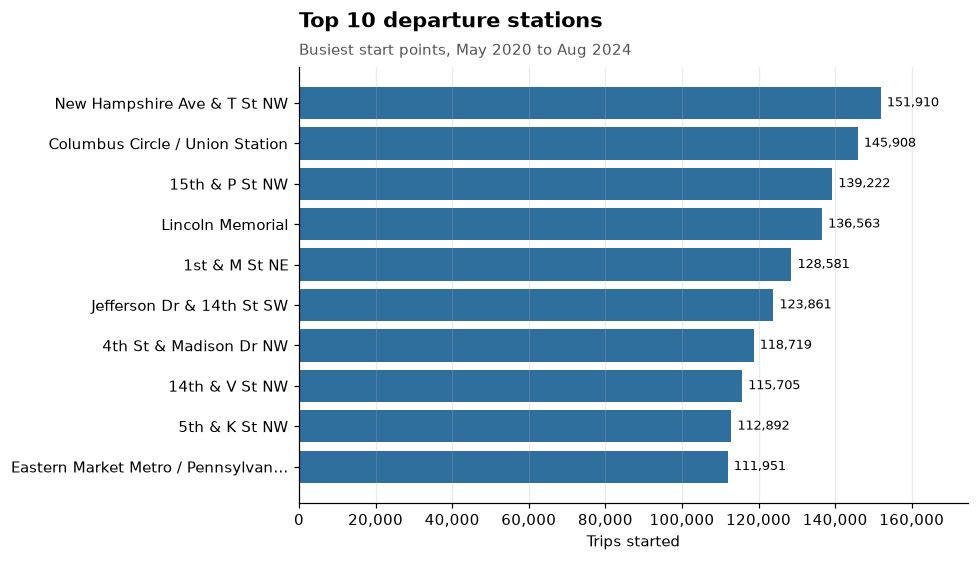

In [52]:
# Departures per station, plus first/last active day so we can judge under-use fairly
stations = run("""
SELECT start_station_id          AS station_id,
       MAX(start_station_name)   AS station_name,
       COUNT(*)                  AS departures,
       AVG(start_lat)            AS lat,
       AVG(start_lng)            AS lng,
       MIN(trip_date)            AS first_day,
       MAX(trip_date)            AS last_day
FROM trips_clean
WHERE start_station_id IS NOT NULL
GROUP BY start_station_id
""")
arrivals = run("""
SELECT end_station_id AS station_id, COUNT(*) AS arrivals
FROM trips_clean
WHERE end_station_id IS NOT NULL
GROUP BY end_station_id
""")

top10 = (stations.nlargest(10, "departures")[["station_name", "departures"]]
         .rename(columns={"departures": "trip_count"}))
plots.plot_station_bars(top10, "trip_count", "Top 10 departure stations",
                        "Busiest start points, May 2020 to Aug 2024", xlabel="Trips started",
                        save_path=f"{IMG}/04_top_10_departure_stations.png")
plt.show()

Compare *established* stations (active for at least a year and still active at the end of the data) and rank them by **trips per active day**.

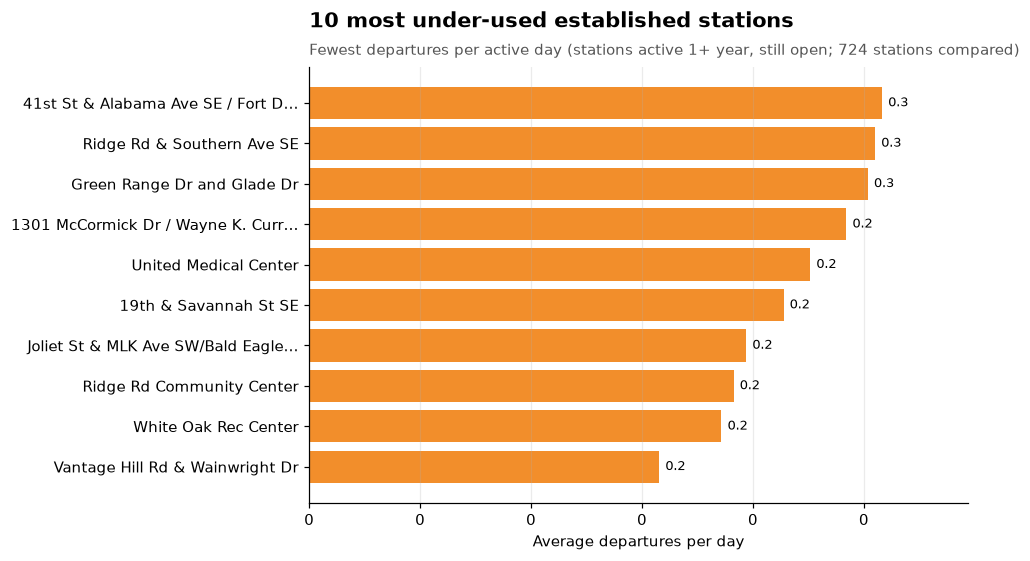

Median established station: 5.2 departures/day. The 10 least-used average 0.2/day.


In [53]:
stations["first_day"] = pd.to_datetime(stations["first_day"])
stations["last_day"] = pd.to_datetime(stations["last_day"])
stations["active_days"] = (stations["last_day"] - stations["first_day"]).dt.days + 1
stations["trips_per_day"] = stations["departures"] / stations["active_days"]

data_end = pd.to_datetime(daily["trip_date"]).max()
established = stations[(stations["active_days"] >= 365) &
                       (stations["last_day"] >= data_end - pd.Timedelta(days=30))].copy()
under = established.nsmallest(10, "trips_per_day")

plots.plot_station_bars(under, "trips_per_day", "10 most under-used established stations",
                        f"Fewest departures per active day (stations active 1+ year, still open; {len(established)} stations compared)",
                        color=plots.COLORS["casual"], xlabel="Average departures per day",
                        save_path=f"{IMG}/13_least_used_stations.png")
plt.show()

median_tpd = established["trips_per_day"].median()
print(f"Median established station: {median_tpd:.1f} departures/day. "
      f"The 10 least-used average {under['trips_per_day'].mean():.1f}/day.")

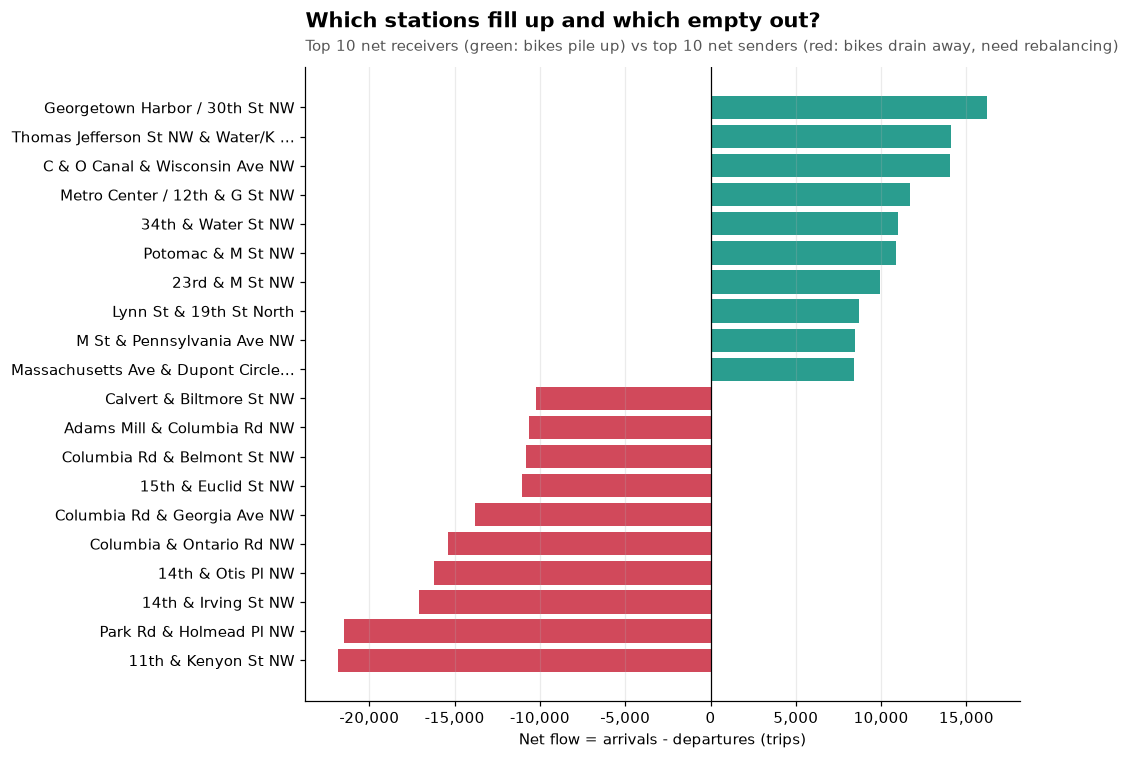

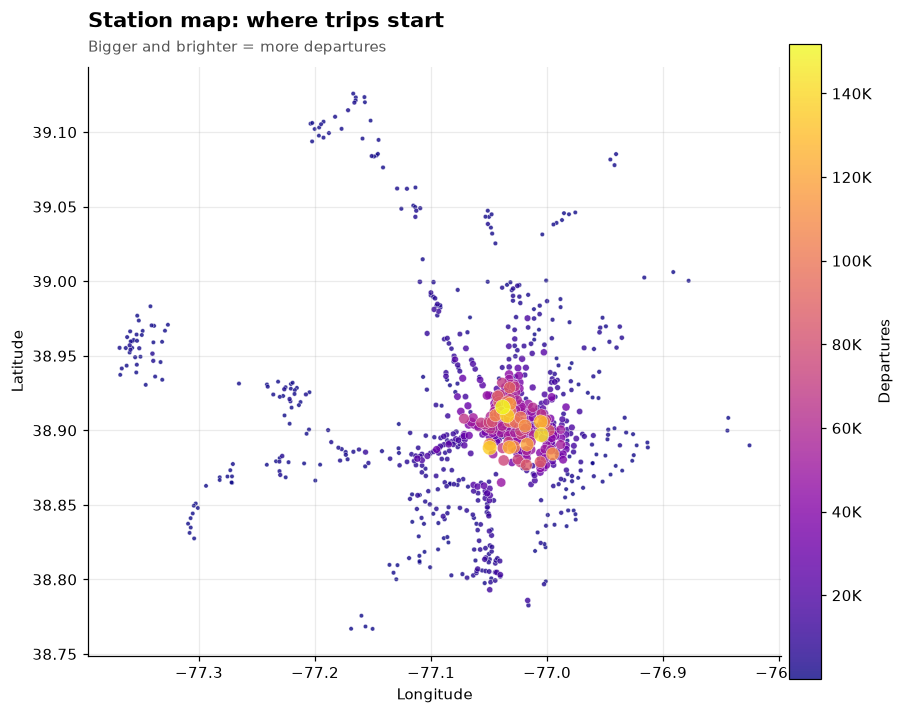

389 stations receive more bikes than they send; 418 lose bikes.
Biggest net receiver: Georgetown Harbor / 30th St NW (+16,217).
Biggest net sender  : 11th & Kenyon St NW (-21,841).


In [54]:
# Net flow = arrivals - departures (positive: bikes pile up, negative: station drains)
names = run("SELECT station_id, station_name FROM station_list").drop_duplicates("station_id")
flow = (stations[["station_id", "station_name", "departures"]]
        .merge(arrivals, on="station_id", how="outer")
        .merge(names, on="station_id", how="left", suffixes=("", "_list")))
flow["station_name"] = flow["station_name"].fillna(flow["station_name_list"]).fillna(flow["station_id"].astype(str))
flow[["departures", "arrivals"]] = flow[["departures", "arrivals"]].fillna(0)
flow["net_flow"] = flow["arrivals"] - flow["departures"]

plots.plot_net_flow(flow, n=10, save_path=f"{IMG}/14_net_flow_stations.png")
plt.show()

plots.plot_station_map(stations, f"{IMG}/15_station_map.png")
plt.show()

fills = flow.loc[flow["net_flow"].idxmax()]
drains = flow.loc[flow["net_flow"].idxmin()]
print(f"{(flow['net_flow'] > 0).sum()} stations receive more bikes than they send; {(flow['net_flow'] < 0).sum()} lose bikes.")
print(f"Biggest net receiver: {fills['station_name']} (+{fills['net_flow']:,.0f}).")
print(f"Biggest net sender  : {drains['station_name']} ({drains['net_flow']:,.0f}).")

## 6.5 Does weather matter?

Daily trip counts are joined to the daily weather table. The raw `conditions` field has dozens of combinations (e.g. *"Snow, Rain, Freezing Drizzle/Freezing Rain, Ice, Overcast"*), so grouped them into five categories.


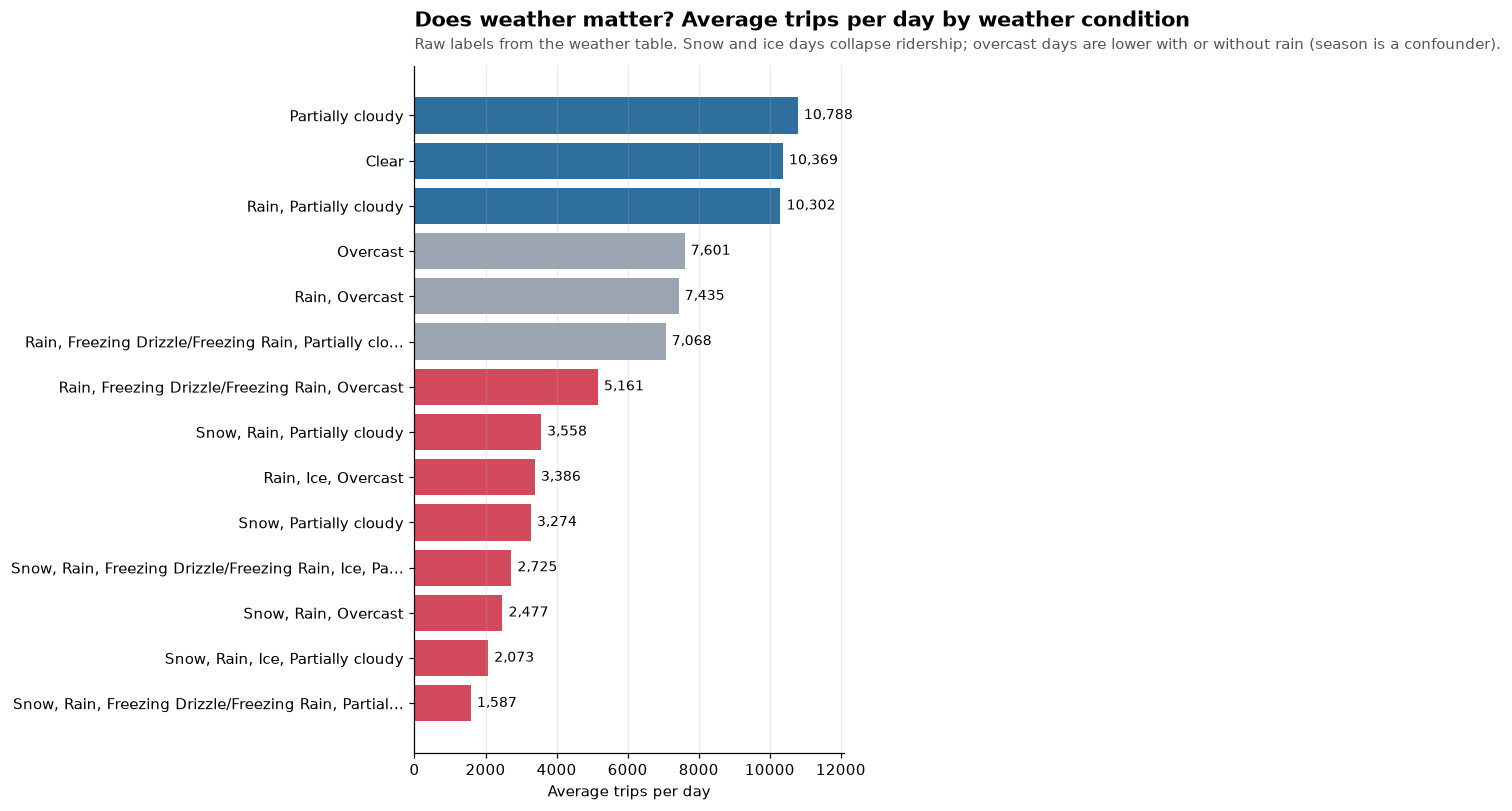

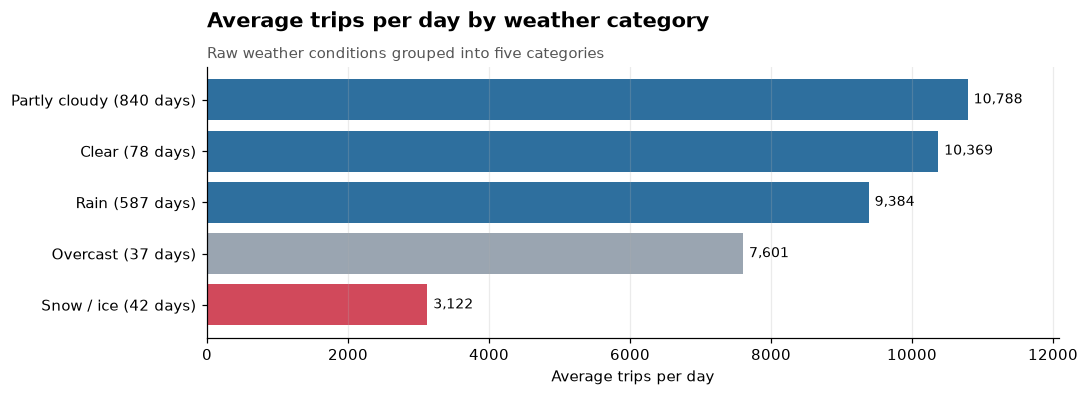

In [55]:
wx = run("SELECT datetime AS trip_date, temp, tempmax, tempmin, precip, snow, windspeed, conditions FROM weather")
dw = daily[["trip_date", "trips"]].merge(wx, on="trip_date", how="inner")


def simplify(c):
    c = str(c)
    if any(k in c for k in ("Snow", "Ice", "Freezing")):
        return "Snow / ice"
    if "Rain" in c:
        return "Rain"
    if "Overcast" in c:
        return "Overcast"
    if "Partially cloudy" in c:
        return "Partly cloudy"
    if "Clear" in c:
        return "Clear"
    return "Other"


dw["category"] = dw["conditions"].map(simplify)
dw["rainy"] = dw["precip"].fillna(0) >= 1          # at least 1 mm of precipitation
dw["snowy"] = dw["snow"].fillna(0) > 0
dw["month"] = pd.to_datetime(dw["trip_date"]).dt.month

raw_conditions = dw.groupby("conditions", as_index=False).agg(avg_trips_per_day=("trips", "mean"))
plots.plot_weather_bars(raw_conditions, "conditions",
                        title="Does weather matter? Average trips per day by weather condition",
                        subtitle="Raw labels from the weather table. Snow and ice days collapse ridership; overcast days are lower with or without rain (season is a confounder).",
                        save_path=f"{IMG}/05_weather_raw_conditions.png", max_label=52)
plt.show()

weather_cat = (dw.groupby("category")
                 .agg(avg_trips_per_day=("trips", "mean"), days=("trips", "size"))
                 .reset_index())
weather_cat["label"] = weather_cat["category"] + " (" + weather_cat["days"].astype(str) + " days)"

plots.plot_weather_bars(weather_cat, "label",
                        title="Average trips per day by weather category",
                        subtitle="Raw weather conditions grouped into five categories",
                        save_path=f"{IMG}/16_weather_category.png")
plt.show()

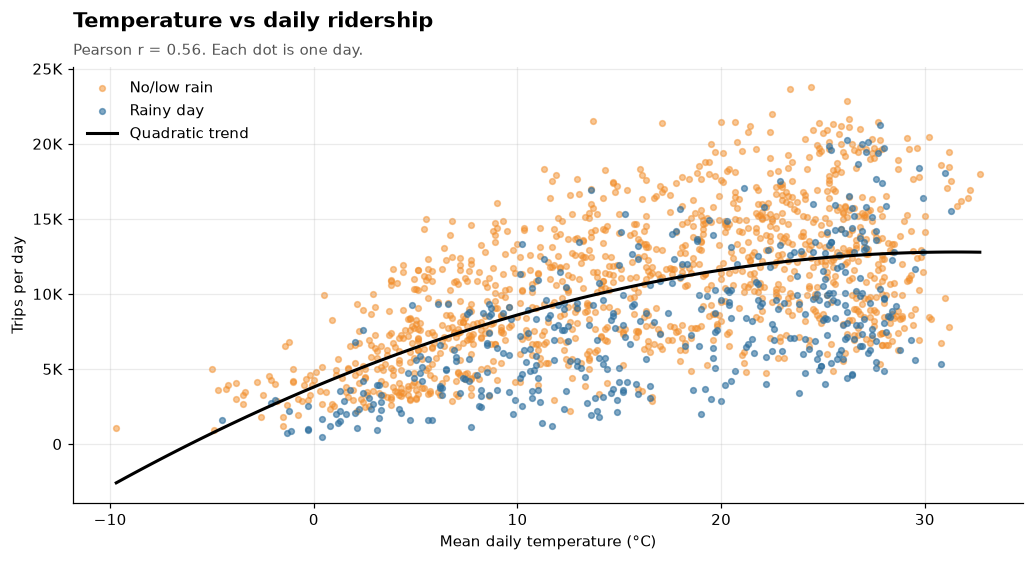

Jun-Sep (same season): rainy days average 10,289 trips vs 13,128 on dry days (-22%).
Dec-Mar: snow days average 3,056 trips vs 7,019 without snow (-56%).
Correlation between mean daily temperature and trips: r = 0.56


,avg_trips_per_day,days
temp,,
<0 C,"3,165.58",45
0-10 C,"6,655.17",406
10-20 C,"10,125.30",494
20-25 C,"12,407.68",287
>25 C,"12,453.42",352


In [56]:
plots.plot_temperature(dw, f"{IMG}/17_temperature_vs_trips.png")
plt.show()

# Computed takeaways
def pct(a, b):
    return (a / b - 1) * 100

summer = dw[dw["month"].isin([6, 7, 8, 9])]
wet, dry = summer[summer["rainy"]]["trips"].mean(), summer[~summer["rainy"]]["trips"].mean()
print(f"Jun-Sep (same season): rainy days average {wet:,.0f} trips vs {dry:,.0f} on dry days ({pct(wet, dry):+.0f}%).")

winter = dw[dw["month"].isin([12, 1, 2, 3])]
if winter["snowy"].any():
    sn, no_sn = winter[winter["snowy"]]["trips"].mean(), winter[~winter["snowy"]]["trips"].mean()
    print(f"Dec-Mar: snow days average {sn:,.0f} trips vs {no_sn:,.0f} without snow ({pct(sn, no_sn):+.0f}%).")

r = np.corrcoef(dw["temp"].dropna(), dw.loc[dw["temp"].notna(), "trips"])[0, 1]
print(f"Correlation between mean daily temperature and trips: r = {r:.2f}")

bins = pd.cut(dw["temp"], [-30, 0, 10, 20, 25, 50], labels=["<0 C", "0-10 C", "10-20 C", "20-25 C", ">25 C"])
display(dw.groupby(bins, observed=True)["trips"].agg(["mean", "count"]).rename(columns={"mean": "avg_trips_per_day", "count": "days"}))

## 6.6 Executive dashboard

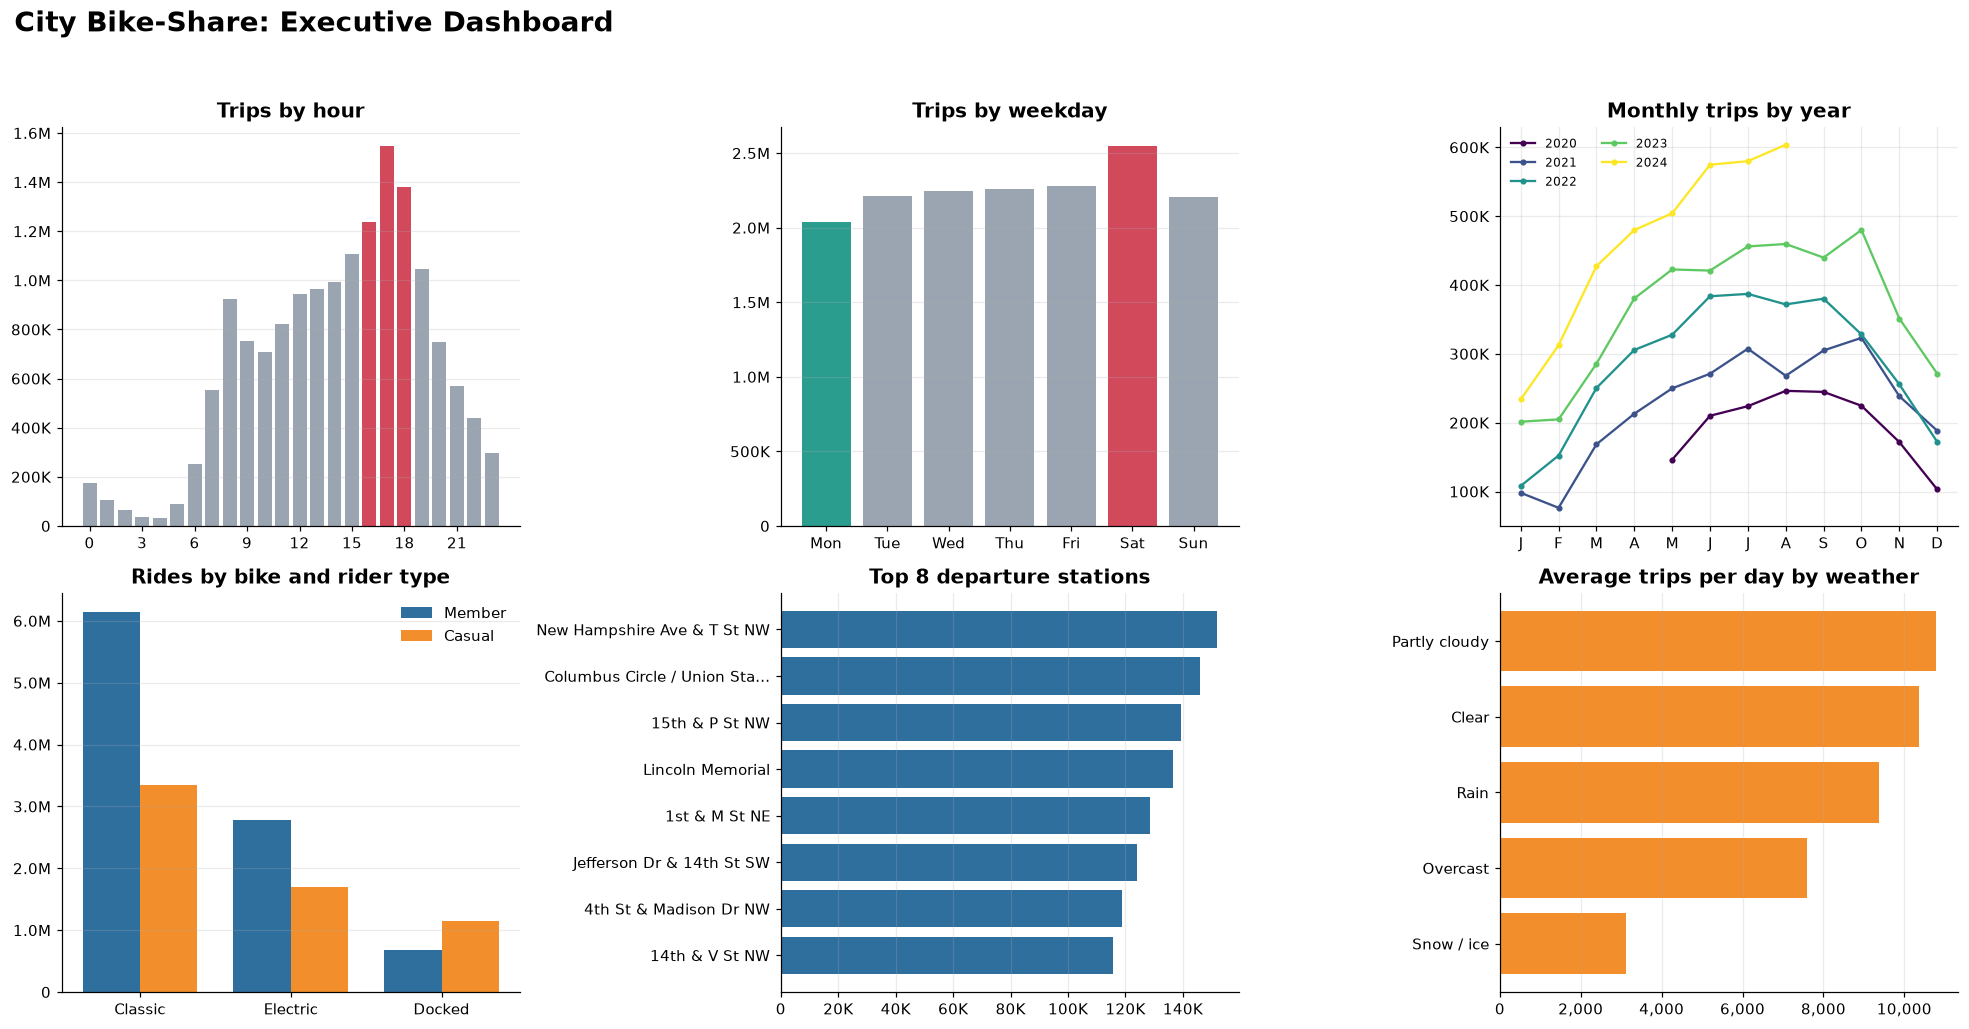

In [57]:
plots.plot_dashboard(hourly_overall, weekday, monthly, fleet, top10,
                     weather_cat[["category", "avg_trips_per_day"]],
                     save_path=f"{IMG}/00_dashboard.png")
plt.show()

# 7. Key Findings

In [62]:
date_min, date_max = daily["trip_date"].min(), daily["trip_date"].max()
peak_h = hourly_overall.loc[hourly_overall["number_of_trips"].idxmax()]
wk = weekday.set_index("Day")["Number_of_Trips"]
elec = fleet[fleet["rideable_type"] == "electric_bike"]
classic = fleet[fleet["rideable_type"] == "classic_bike"]
avg_e = elec["total_min"].sum() / elec["number_of_rides"].sum()
avg_c = classic["total_min"].sum() / classic["number_of_rides"].sum()

findings = [
    f"**Scale:** {n_clean:,} valid trips between {date_min} and {date_max} "
    f"({(n_raw - n_clean) / n_raw:.1%} of raw rows removed as invalid).",
    f"**Riders:** members take {by_rider['member']:.0%} of rides, casual riders {by_rider['casual']:.0%}.",
    f"**Peak hour:** {int(peak_h['hour_of_day']):02d}:00 is the busiest hour ({peak_h['number_of_trips']:,.0f} trips); "
    f"there is a second peak in the morning around {int(am_peak['hour_of_day']):02d}:00.",
    f"**Weekdays:** {wk.idxmax()} is the busiest day and {wk.idxmin()} the quietest "
    f"({1 - wk.min() / wk.max():.0%} fewer trips than the busiest day).",
    f"**Seasonality:** {pd.Timestamp(2000, int(per_day.idxmax()), 1):%B} is the strongest month "
    f"({per_day.max():,.0f} trips/day on average) and {pd.Timestamp(2000, int(per_day.idxmin()), 1):%B} the weakest "
    f"({per_day.min():,.0f}).",
    f"**Trip length:** casual trips average {avg_by_rider['casual']:.1f} min vs {avg_by_rider['member']:.1f} min for members "
    f"({avg_by_rider['casual'] / avg_by_rider['member']:.1f}x longer).",
    f"**Electric vs classic:** electric bikes account for {by_bike.get('electric_bike', 0):.0%} of rides; "
    f"average trip {avg_e:.1f} min vs {avg_c:.1f} min on classic bikes.",
    f"**Busiest station:** {top10.iloc[0]['station_name']} ({top10.iloc[0]['trip_count']:,.0f} departures).",
    f"**Rebalancing:** {fills['station_name']} gains the most bikes (+{fills['net_flow']:,.0f}); "
    f"{drains['station_name']} loses the most ({drains['net_flow']:,.0f}).",
    f"**Weather:** on Jun-Sep days with 1 mm+ of rain, ridership is {pct(wet, dry):+.0f}% vs dry days; "
    f"temperature and daily trips correlate at r = {r:.2f}.",
]
if winter["snowy"].any():
    findings.append(f"**Snow:** on snowy winter days ridership is {pct(sn, no_sn):+.0f}% vs non-snow winter days.")

for f in findings:
    print("-", f)

os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
with open(os.path.join(ROOT, "reports", "key_findings.md"), "w", encoding="utf-8") as fh:
    fh.write("# Key findings\n\n_Generated by notebooks/City_Bike_Share_Analysis.ipynb_\n\n")
    fh.write("\n".join(f"- {f}" for f in findings) + "\n")
print("\nSaved reports/key_findings.md")

- **Scale:** 15,790,956 valid trips between 2020-05-01 and 2024-08-31 (1.8% of raw rows removed as invalid).
- **Riders:** members take 61% of rides, casual riders 39%.
- **Peak hour:** 17:00 is the busiest hour (1,548,736 trips); there is a second peak in the morning around 08:00.
- **Weekdays:** Saturday is the busiest day and Monday the quietest (20% fewer trips than the busiest day).
- **Seasonality:** July is the strongest month (12,610 trips/day on average) and January the weakest (5,172).
- **Trip length:** casual trips average 28.3 min vs 13.4 min for members (2.1x longer).
- **Electric vs classic:** electric bikes account for 28% of rides; average trip 15.1 min vs 18.3 min on classic bikes.
- **Busiest station:** New Hampshire Ave & T St NW (151,910 departures).
- **Rebalancing:** Georgetown Harbor / 30th St NW gains the most bikes (+16,217); 11th & Kenyon St NW loses the most (-21,841).
- **Weather:** on Jun-Sep days with 1 mm+ of rain, ridership is -22% vs dry days; temperat